<a href="https://colab.research.google.com/github/EvezMemmedov/data-science-notebooks/blob/main/linear_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

In [ ]:
np.random.seed(42)

m = 100
X = 2 * np.random.rand(m, 1)
y = 4 + 3 * X + np.random.randn(m, 1)

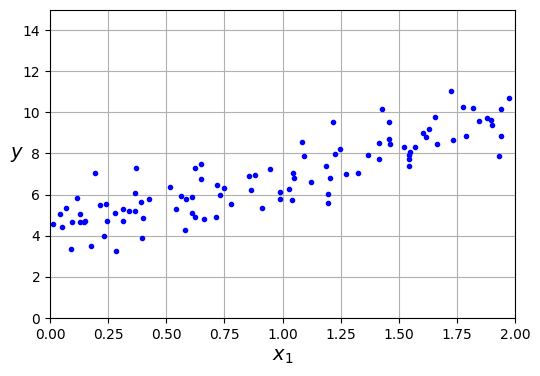

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(X, y, 'b.')
plt.xlabel('$x_1$')
plt.ylabel('$y$', rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid();

In [ ]:
matrix_a = np.array([[1, 2],
                     [3, 4]])

matrix_b = np.array([[5, 6],
                     [7, 8]])

result  = matrix_a @ matrix_b
result1 = np.dot(matrix_a, matrix_b)
# np.matmul()   -> eyni nəticə
# matrix_a * matrix_b -> elementwise (element-element)

print('Matrix A:')
print(matrix_a)
print('\nMatrix b:')
print(matrix_b)
print('\nResult of Matrix multiplication (A @ B):')
print(result1)

Matrix A:
[[1 2]
 [3 4]]

Matrix b:
[[5 6]
 [7 8]]

Result of Matrix multiplication (A @ B):
[[19 22]
 [43 50]]


In [ ]:
from sklearn.preprocessing import add_dummy_feature

X_b = add_dummy_feature(X)   # wx + b-də b olsun deyə

theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

In [ ]:
theta_best   # w and b values
# array([[4.215], [2.770]])

array([[4.21509616],
       [2.77011339]])

In [ ]:
X_new = np.array([[0], [2]])
X_new_b = add_dummy_feature(X_new)

y_predict = X_new_b @ theta_best
y_predict
# array([[4.215], [9.755]])

array([[4.21509616],
       [9.75532293]])

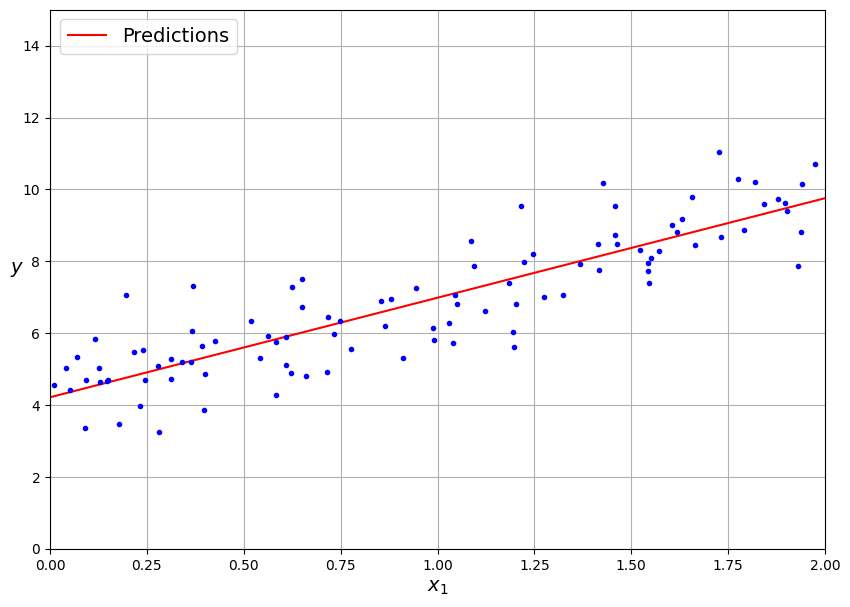

In [ ]:
plt.figure(figsize=(10, 7))
plt.plot(X_new, y_predict, 'r-', label='Predictions')
plt.plot(X, y, 'b.')

plt.xlabel('$x_1$')
plt.ylabel('$y$', rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid()
plt.legend(loc='upper left')

plt.show()

In [ ]:
X.shape, X.T.shape

((100, 1), (1, 100))

In [ ]:
def linreg(X, y):
    return np.linalg.inv(X.T @ X) @ X.T @ y

print(linreg(X_b, y))

[[4.21509616]
 [2.77011339]]


In [ ]:
# y = 3x + 4z + 5

dict1 = {
    'x': [8, 9, 4, 5, 6],
    'z': [1, 6, 12, 7, 6],
    'y': [33, 56, 65, 48, 47]
}

temp_df = pd.DataFrame(dict1, columns=dict1.keys())
X_temp = temp_df.drop(['y'], axis=1)
y_temp = temp_df['y'].copy()

X_temp = add_dummy_feature(X_temp)

np.linalg.inv(X_temp.T @ X_temp) @ X_temp.T @ y_temp
# array([5., 3., 4.])

array([5., 3., 4.])

In [ ]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, y)
lin_reg.intercept_, lin_reg.coef_
# (array([4.215]), array([[2.770]]))

(array([4.21509616]), array([[2.77011339]]))

In [ ]:
# y = 3x + 4z + 5

dict1 = {
    'x': [8, 9, 4, 5, 6],
    'z': [1, 6, 12, 7, 6],
    'y': [33, 56, 65, 48, 47]
}

temp_df = pd.DataFrame(dict1, columns=dict1.keys())
X_temp = temp_df.drop(['y'], axis=1)
y_temp = temp_df['y'].copy()

X_temp = add_dummy_feature(X_temp)

np.linalg.inv(X_temp.T @ X_temp) @ X_temp.T @ y_temp
# array([5., 3., 4.])

array([5., 3., 4.])

In [ ]:
# y = 3x + 4z + 5

dict1 = {
    'x': [8, 9, 4, 5, 6],
    'z': [1, 6, 12, 7, 6],
    'y': [33, 56, 65, 48, 47]
}

temp_df = pd.DataFrame(dict1, columns=dict1.keys())
X_temp = temp_df.drop(['y'], axis=1)
y_temp = temp_df['y'].copy()

X_temp = add_dummy_feature(X_temp)

np.linalg.inv(X_temp.T @ X_temp) @ X_temp.T @ y_temp
# array([5., 3., 4.])

array([5., 3., 4.])

Gradient Descent

In [ ]:
eta = 0.1 #learning rate
n_epochs = 1000
m = len(X_b)   # number of instances

np.random.seed(42)
theta = np.random.randn(2,1)   # randomly initialize model parameters

for epoch in range(n_epochs):
  gradient = 1 / m * 2 * X_b.T @ (X_b @ theta - y)
  theta = theta - eta * gradient

In [ ]:
theta

array([[4.21509616],
       [2.77011339]])

Stochastic Gradient Descend

In [ ]:
np.random.seed(42)
eta = 0.1
m = len(X_b)
theta = np.random.randn(2, 1)

for epoch in range(n_epochs):
  for iteration in range(m):
    random_index = np.random.randint(m)
    xi = X_b[random_index : random_index + 1]
    yi = y[random_index : random_index + 1]
    gradients = 2 * xi.T @ (xi @ theta -yi)
    theta = theta - eta * gradients

In [ ]:
theta

array([[4.17686315],
       [2.85986577]])

eynisi asagida

In [ ]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(max_iter = 1000, tol = 1e-5, penalty = None, eta0 = 0.01,
                       n_iter_no_change=100, random_state=42)
sgd_reg.fit(X, y.ravel())

SGDRegressor(n_iter_no_change=100, penalty=None, random_state=42, tol=1e-05)

In [ ]:
sgd_reg.intercept_, sgd_reg.coef_

(array([4.21278812]), array([2.77270267]))

Mini Batch Gradient Descend

In [ ]:
from math import ceil

n_epochs = 50
eta = 0.1
m = len(X_b)
minibatch_size = 20
n_batches_per_epoch = ceil(m / minibatch_size)

np.random.seed(42)
theta = np.random.randn(2, 1)

for epoch in range(n_epochs):
  shuffled_indices = np.random.permutation(m)
  X_b_shuffled = X_b[shuffled_indices]
  y_shuffled = y[shuffled_indices]
  for iteration in range(0, n_batches_per_epoch):
    idx = iteration * minibatch_size
    xi = X_b_shuffled[idx : idx + minibatch_size]
    yi = y_shuffled[idx : idx + minibatch_size]
    gradients = 2 / minibatch_size * xi.T @ (xi @ theta - yi)
    theta = theta - eta * gradients

In [ ]:
theta

array([[4.22023943],
       [2.7704472 ]])